# Lab: Regression Analysis

### Before you start:

* Read the README.md file
* Comment as much as you can and use the resources (README.md file) 

Happy learning!

## Challenge 1
I work at a coding bootcamp, and I have developed a theory that the younger my students are, the more often they are late to class. In order to test my hypothesis, I have collected some data in the following table:

| StudentID | Age | Tardies |
|--------|-----|------------|
| 1      | 17  | 10         |
| 2      | 51  | 1          |
| 3      | 27  | 5          |
| 4      | 21  | 9         |
| 5      | 36  |  4         |
| 6      | 48  |  2         |
| 7      | 19  |  9         |
| 8      | 26  | 6          |
| 9      | 54  |  0         |
| 10     | 30  |  3         |

In [ ]:
import pandas as pd
import numpy as np
import plotly.express as px
import statsmodels.formula.api as smf
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import seaborn as sns

Use this command to create a dataframe with the data provided in the table. 
~~~~
student_data = pd.DataFrame({'Age': [17,51,27,21,36,48,19,26,54,30], 'Tardies': [10,1,5,9,4,2,9,6,0,3]})
~~~~

In [3]:
# Your code here. 
student_data = pd.DataFrame({'Age': [17,51,27,21,36,48,19,26,54,30], 
                             'Tardies': [10,1,5,9,4,2,9,6,0,3]})

Draw a dispersion diagram (scatter plot) for the data.

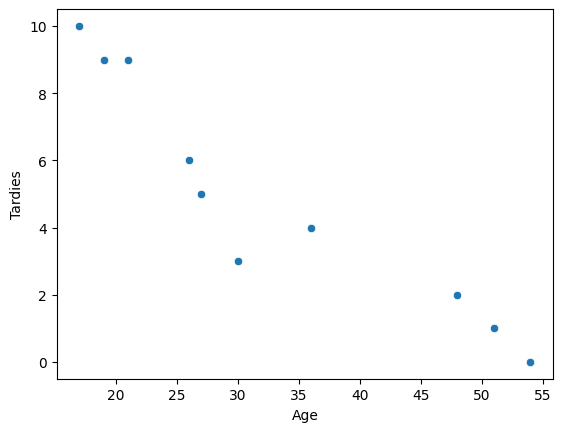

In [4]:
# Your code here

sns.scatterplot(student_data,
                x = "Age",
                y = "Tardies")
plt.show()

Do you see a trend? Can you make any hypotheses about the relationship between age and number of tardies?

*your explanation here*

The age is inversely proportional to the tardiness of the students.

Calculate the covariance and correlation of the variables in your plot. What is the difference between these two measures? Compare their values. What do they tell you in this case? Add your responses as comments after your code.

In [5]:
# your code here
cov = student_data.cov()

cov


,Age,Tardies
Age,187.655556,-45.566667
Tardies,-45.566667,12.544444


In [6]:
corr = student_data.corr()
corr

,Age,Tardies
Age,1.000000,-0.939163
Tardies,-0.939163,1.000000


In [7]:
# The correlation chrecks for the direction and strength of the connection between 2 variables and musr range between -1 to +1.
#-0.939 is a strong negative correlation. 
#Covariance on the other hand describes the direction of the relationship and is sensitive to scaling.
#-45.57 is in agreement with the correlation, therefore, the tardiness is inversely proportional to the age.

Build a regression model for this data. What will be your outcome variable? What type of regression are you using? Add your responses as comments after your code.

In [8]:
# your explanation here
x = np.array(student_data["Age"]).reshape(-1,1)
y = np.array(student_data["Tardies"]).reshape(-1,1)
student_reg = LinearRegression()
student_reg.fit(x, y)




LinearRegression()

Plot your regression model on your scatter plot.

<Axes: xlabel='Age', ylabel='Tardies'>

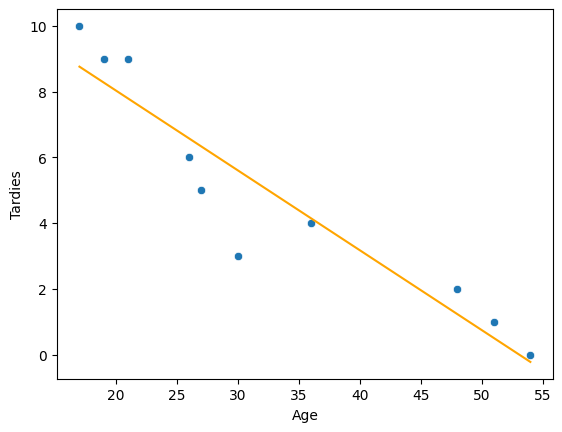

In [9]:
# Your code here.
y_pred = student_reg.predict(x)
sns.scatterplot(student_data,
                x = "Age",
                y = "Tardies"
)

sns.lineplot(
    x = student_data["Age"],
    y = y_pred.ravel(),
    color = "orange"
)

In [10]:
# I used linear regression to predict the outcome of the age for its level of tardiness.

Interpret the results of your model. What can conclusions can you draw from your model and how confident in these conclusions are you? Can we say that age is a good predictor of tardiness? Add your responses as comments after your code.

*your explanation here*

In [11]:
# Checking for the model accurracy:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
mae = mean_absolute_error(y, y_pred)
rmse = np.sqrt(mean_squared_error(y, y_pred))
r2 = r2_score(y, y_pred)

print(f"MAE:{mae:.3f}",
      f"RMSE:{rmse:.3f}",
      f"R_squared: {r2:.3f}"
)

MAE:0.932 RMSE:1.154 R_squared: 0.882


The accuracy of the linear regression model I chose shows that:
- MAE is 0.93, hence it is close to predicting an age based on tardiness by 0.9 years up and down the target age.
- RMSE = 1.15 means that the penalty of having a wring age predicted is about 1.15 years, this affects situations like outliers or anomalies.
- R2 = 0.882 is a strong indication that the model can predict 88% of the time related to the age and tardiness.

## Challenge 2
For the second part of this lab, we will use the vehicles.csv data set. You can find a copy of the dataset in the git hub folder. This dataset includes variables related to vehicle characteristics, including the model, make, and energy efficiency standards, as well as each car's CO2 emissions. As discussed in class the goal of this exercise is to predict vehicles' CO2 emissions based on several independent variables. 

In [29]:
# Import any libraries you may need & the data
from pathlib import Path
data = Path('../vehicles.csv')
vehicles = pd.read_csv(data)

Let's use the following variables for our analysis: Year, Cylinders, Fuel Barrels/Year, Combined MPG, and Fuel Cost/Year. We will use 'CO2 Emission Grams/Mile' as our outcome variable. 

Calculate the correlations between each of these variables and the outcome. Which variable do you think will be the most important in determining CO2 emissions? Which provides the least amount of helpful information for determining CO2 emissions? Add your responses as comments after your code.

In [63]:
# Your code here.

#vh = vehicles.loc[:, ['Year', 'Cylinders', 'Fuel Barrels/Year', 'Combined MPG', 'Fuel Cost/Year']
vh = vehicles.select_dtypes(include=['number']).dropna()
vh = vh.drop(['Engine Displacement'], axis=1)#'CO2 Emission Grams/Mile'], axis =1)
vh_corr = vh.corr()
vh_corr

,Year,Cylinders,Fuel Barrels/Year,City MPG,Highway MPG,Combined MPG,CO2 Emission Grams/Mile,Fuel Cost/Year
Year,1.000000,0.082469,-0.221084,0.161818,0.267259,0.204751,-0.222300,-0.091913
Cylinders,0.082469,1.000000,0.739517,-0.703866,-0.650287,-0.698648,0.752393,0.778153
Fuel Barrels/Year,-0.221084,0.739517,1.000000,-0.877752,-0.909664,-0.909743,0.986189,0.916208
City MPG,0.161818,-0.703866,-0.877752,1.000000,0.923856,0.985457,-0.894139,-0.858645
Highway MPG,0.267259,-0.650287,-0.909664,0.923856,1.000000,0.969392,-0.926405,-0.851404
Combined MPG,0.204751,-0.698648,-0.909743,0.985457,0.969392,1.000000,-0.926229,-0.875185
CO2 Emission Grams/Mile,-0.222300,0.752393,0.986189,-0.894139,-0.926405,-0.926229,1.000000,0.930865
Fuel Cost/Year,-0.091913,0.778153,0.916208,-0.858645,-0.851404,-0.875185,0.930865,1.000000


In [68]:
# target = "CO2 Emission [Grams/Mile]"

target = "CO2 Emission Grams/Mile"
id_corr = vh_corr[target].drop(target)
best_feature = id_corr.abs().idxmax()
best_corr = id_corr.loc[best_feature]
worst_feature = id_corr.abs().idxmin()
worst_corr = id_corr.loc[worst_feature]
print(f'{best_feature} , {best_corr}')
print(f'Worst: {worst_feature}, {worst_corr}')

Fuel Barrels/Year , 0.9861886621428763
Worst: Year, -0.22229960295056833


Build a regression model for this data. What type of regression are you using? Add your responses as comments after your code.

<Axes: xlabel='Fuel Barrels/Year', ylabel='CO2 Emission Grams/Mile'>

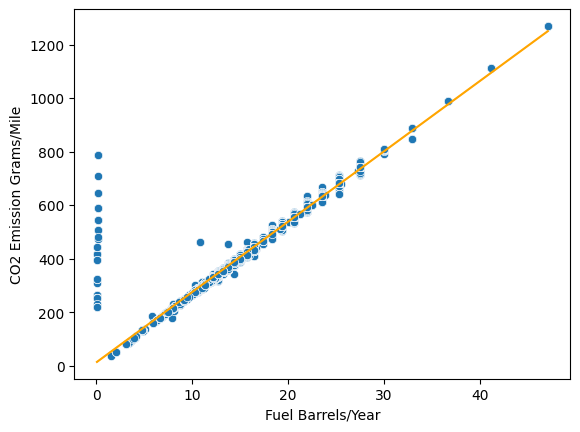

In [ ]:
# Your code here.
# Regression used: Linear
xv = np.array(vh["Fuel Barrels/Year"]).reshape(-1,1)
yv = np.array(vh["CO2 Emission Grams/Mile"]).reshape(-1,1)
vh_reg = LinearRegression()
vh_reg.fit(xv, yv)
y_pred = vh_reg.predict(xv)
sns.scatterplot(vh,
                x = "Fuel Barrels/Year",
                y = "CO2 Emission Grams/Mile"
)

sns.lineplot(
    x = vh["Fuel Barrels/Year"],
    y = y_pred.ravel(),
    color = "orange"
)

Print your regression summary, and interpret the results. What are the most important varibles in your model and why? What can conclusions can you draw from your model and how confident in these conclusions are you? Add your responses as comments after your code.

In [ ]:
# Your code here.
vh_emissions = vh[['Fuel Barrels/Year','CO2 Emission Grams/Mile']]
corr_vh = vh_emissions.corr()
corr_vh

,Fuel Barrels/Year,CO2 Emission Grams/Mile
Fuel Barrels/Year,1.000000,0.986189
CO2 Emission Grams/Mile,0.986189,1.000000


In [80]:
mae = mean_absolute_error(yv, y_pred)
rmse = np.sqrt(mean_squared_error(yv, y_pred))
r2 = r2_score(yv, y_pred)

print(f"MAE:{mae:.3f}",
      f"RMSE:{rmse:.3f}",
      f"R_squared: {r2:.3f}"
)

MAE:3.771 RMSE:19.719 R_squared: 0.973


In [81]:
# The MAE is high for the prediction, the RMSE is also high and shows that the model is not equipped to handle outliers.
# R2 is close to 1, which is a good indicator that the model can predict within a specificed bound. In this case, removing the 0 Barrels/Year data should improve the model's RMSE and MAE.

## Bonus Challenge: Error Analysis

I am suspicious about the last few parties I have thrown: it seems that the more people I invite the more people are unable to attend. To know if my hunch is supported by data, I have decided to do an analysis. I have collected my data in the table below, where X is the number of people I invited, and Y is the number of people who attended. 

|  X |  Y |
|----|----|
| 1  |  1 |
| 3  |  2 |
| 4  |  4 |
| 6  |  4 |
| 8  |  5 |
| 9  |  7 |
| 11 |  8 |
| 14 |  13 |

We want to know if the relationship modeled by the two random variables is linear or not, and therefore if it is appropriate to model it with a linear regression. 
First, build a dataframe with the data. 

In [ ]:
# Your code here.


attendance = pd.DataFrame({'Invitation': [1,3,4,6,8,9,11,14], 
                             'Attendance': [1,2,4,4,5,7,8,13]})



,Invitation,Attendance
0,1,1
1,3,2
2,4,4
3,6,4
4,8,5
5,9,7
6,11,8
7,14,13


Draw a dispersion diagram (scatter plot) for the data, and fit a regression line.

<Axes: xlabel='Invitation', ylabel='Attendance'>

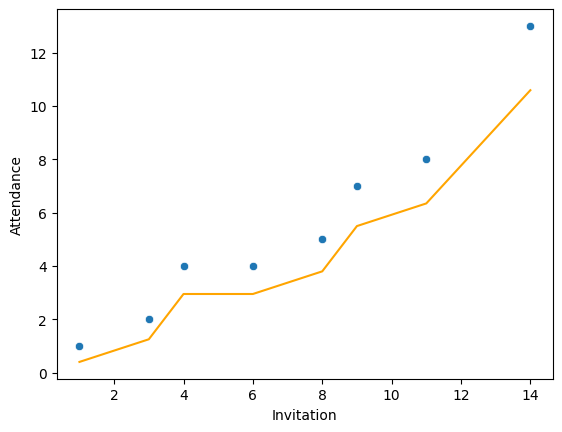

In [99]:
# Your code here.


#from sklearn.linear_model import PolynomialRegression
#regression

xa = np.array(attendance['Invitation']).reshape(-1,1)
ya = np.array(attendance['Attendance']).reshape(-1,1)

attend_reg = LinearRegression()
attend_reg.fit(xa, ya)

y_pred_att = attend_reg.predict(ya)

sns.scatterplot(
    data = attendance,
    x = 'Invitation',
    y = 'Attendance'
)

sns.lineplot(
    x = attendance['Invitation'],
    y = y_pred_att.ravel(),
    color = "orange"
)


What do you see? What does this plot tell you about the likely relationship between the variables? Print the results from your regression.

*your explanation here*

In [100]:
mae = mean_absolute_error(ya, y_pred_att)
rmse = np.sqrt(mean_squared_error(ya, y_pred_att))
r2 = r2_score(ya, y_pred_att)

print(f"MAE:{mae:.3f}",
      f"RMSE:{rmse:.3f}",
      f"R_squared: {r2:.3f}"
)

MAE:1.273 RMSE:1.383 R_squared: 0.850


Do you see any problematic points, or outliers, in your data? Remove these points and recalculate your regression. Print the new dispersion diagram with your new model and the results of your model. 

In [ ]:
# Your response here.

What changed? Based on the results of the two models and your graphs, what can you say about the form of the data with the problematic point and without it?

*your explanation here*